In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

BASE_DIR = Path(
    r"D:\Veda Internship\Sakshi\Super_Store_DataCleaning"
    r"\COVID19_Global_Impact_Dashboard"
)

DAY_DIR = BASE_DIR / "Day3_Covid19_Global_Impact_Dashboard"

CLEANED_PATH = DAY_DIR / "cleaned_data" / "covid19_cleaned.csv"
DATASET_PATH = DAY_DIR / "Dataset" / "owid-covid-data.csv"

CHART_DIR = DAY_DIR / "charts"
CHART_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_PATH = DAY_DIR / "cleaned_data" / "covid19_day3_analysis.csv"

print("Project folder:", BASE_DIR)
print("Cleaned file exists:", CLEANED_PATH.exists())
print("Original file exists:", DATASET_PATH.exists())


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\traitlets\config\application.py", line 1082, in launch_instance
    app.start()
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\ipykernel\kernelapp.py", line 807,

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.6 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\ipykernel_launcher.py", line 18, in <module>
    app.launch_new_instance()
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\traitlets\config\application.py", line 1082, in launch_instance
    app.start()
  File "C:\Users\HP\AppData\Local\Programs\Python\Python311\Lib\site-packages\ipykernel\kernelapp.py", line 807,

AttributeError: _ARRAY_API not found

Project folder: D:\Veda Internship\Sakshi\Super_Store_DataCleaning\COVID19_Global_Impact_Dashboard
Cleaned file exists: True
Original file exists: True


In [2]:
if CLEANED_PATH.exists():
    df = pd.read_csv(CLEANED_PATH)
else:
    df = pd.read_csv(DATASET_PATH)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

Dataset shape: (395311, 72)

Column names:
['iso_code', 'continent', 'location', 'date', 'total_cases', 'new_cases', 'new_cases_smoothed', 'total_deaths', 'new_deaths', 'new_deaths_smoothed', 'total_cases_per_million', 'new_cases_per_million', 'new_cases_smoothed_per_million', 'total_deaths_per_million', 'new_deaths_per_million', 'new_deaths_smoothed_per_million', 'reproduction_rate', 'icu_patients', 'icu_patients_per_million', 'hosp_patients', 'hosp_patients_per_million', 'weekly_icu_admissions', 'weekly_icu_admissions_per_million', 'weekly_hosp_admissions', 'weekly_hosp_admissions_per_million', 'total_tests', 'new_tests', 'total_tests_per_thousand', 'new_tests_per_thousand', 'new_tests_smoothed', 'new_tests_smoothed_per_thousand', 'positive_rate', 'tests_per_case', 'tests_units', 'total_vaccinations', 'people_vaccinated', 'people_fully_vaccinated', 'total_boosters', 'new_vaccinations', 'new_vaccinations_smoothed', 'total_vaccinations_per_hundred', 'people_vaccinated_per_hundred', 'pe

,iso_code,continent,location,date,total_cases,new_cases,new_cases_smoothed,total_deaths,new_deaths,new_deaths_smoothed,...,population,excess_mortality_cumulative_absolute,excess_mortality_cumulative,excess_mortality,excess_mortality_cumulative_per_million,cases_7day_avg,deaths_7day_avg,cases_per_million,deaths_per_million,case_fatality_rate
0,AFG,Asia,Afghanistan,2020-01-05,0.0,0.0,NaN,0.0,0.0,NaN,...,41128772,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
1,AFG,Asia,Afghanistan,2020-01-06,0.0,0.0,NaN,0.0,0.0,NaN,...,41128772,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
2,AFG,Asia,Afghanistan,2020-01-07,0.0,0.0,NaN,0.0,0.0,NaN,...,41128772,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
3,AFG,Asia,Afghanistan,2020-01-08,0.0,0.0,NaN,0.0,0.0,NaN,...,41128772,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
4,AFG,Asia,Afghanistan,2020-01-09,0.0,0.0,NaN,0.0,0.0,NaN,...,41128772,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN


In [3]:
print("Rows and columns:", df.shape)

print("\nDuplicate rows:", df.duplicated().sum())

print("\nMissing values in important columns:")
important_columns = [
    col for col in [
        "location", "date", "total_cases", "new_cases",
        "total_deaths", "new_deaths", "population",
        "people_vaccinated", "people_fully_vaccinated"
    ]
    if col in df.columns
]

print(df[important_columns].isna().sum())

df["date"] = pd.to_datetime(df["date"], errors="coerce")

df = df.dropna(subset=["location", "date"])
df = df.sort_values(["location", "date"]).copy()

print("\nDate range:")
print(df["date"].min(), "to", df["date"].max())

Rows and columns: (395311, 72)

Duplicate rows: 0

Missing values in important columns:
location                        0
date                            0
total_cases                  5269
new_cases                    6914
total_deaths                 5269
new_deaths                   6465
population                      0
people_vaccinated          332768
people_fully_vaccinated    335858
dtype: int64

Date range:
2020-01-01 00:00:00 to 2024-08-14 00:00:00


In [4]:
required_columns = [
    "location", "date", "total_cases", "new_cases",
    "total_deaths", "new_deaths", "population",
    "people_vaccinated", "people_fully_vaccinated"
]

available_columns = [
    col for col in required_columns if col in df.columns
]

print("Available columns:", available_columns)
print("Missing required columns:",
      sorted(set(required_columns) - set(available_columns)))

Available columns: ['location', 'date', 'total_cases', 'new_cases', 'total_deaths', 'new_deaths', 'population', 'people_vaccinated', 'people_fully_vaccinated']
Missing required columns: []


In [5]:
# Convert available numeric fields to numeric format
numeric_columns = [
    "total_cases", "new_cases",
    "total_deaths", "new_deaths",
    "population", "people_vaccinated",
    "people_fully_vaccinated"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Calculate metrics separately for each country
grouped = df.groupby("location", sort=False)

if "new_cases" in df.columns:
    df["new_cases_7day_avg"] = grouped["new_cases"].transform(
        lambda s: s.rolling(7, min_periods=7).mean()
    )

if "new_deaths" in df.columns:
    df["new_deaths_7day_avg"] = grouped["new_deaths"].transform(
        lambda s: s.rolling(7, min_periods=7).mean()
    )

df[[
    col for col in [
        "location", "date", "new_cases",
        "new_cases_7day_avg", "new_deaths_7day_avg"
    ] if col in df.columns
]].tail()

,location,date,new_cases,new_cases_7day_avg,new_deaths_7day_avg
395306,Zimbabwe,2024-07-31,0.0,0.0,0.0
395307,Zimbabwe,2024-08-01,0.0,0.0,0.0
395308,Zimbabwe,2024-08-02,0.0,0.0,0.0
395309,Zimbabwe,2024-08-03,0.0,0.0,0.0
395310,Zimbabwe,2024-08-04,0.0,0.0,0.0


In [6]:
#Calculate cases and deaths per million
if {"total_cases", "population"}.issubset(df.columns):
    df["cases_per_million"] = (
        df["total_cases"] / df["population"] * 1_000_000
    )

if {"total_deaths", "population"}.issubset(df.columns):
    df["deaths_per_million"] = (
        df["total_deaths"] / df["population"] * 1_000_000
    )

df[[
    col for col in [
        "location", "date", "cases_per_million",
        "deaths_per_million"
    ] if col in df.columns
]].tail()

,location,date,cases_per_million,deaths_per_million
395306,Zimbabwe,2024-07-31,16322.132498,351.704071
395307,Zimbabwe,2024-08-01,16322.132498,351.704071
395308,Zimbabwe,2024-08-02,16322.132498,351.704071
395309,Zimbabwe,2024-08-03,16322.132498,351.704071
395310,Zimbabwe,2024-08-04,16322.132498,351.704071


In [7]:
#Calculate case fatality rate
if {"total_cases", "total_deaths"}.issubset(df.columns):
    df["case_fatality_rate"] = (
        df["total_deaths"]
        .div(df["total_cases"].where(df["total_cases"] > 0))
        * 100
    )

print(df[[
    col for col in [
        "location", "date", "case_fatality_rate"
    ] if col in df.columns
]].tail())

        location       date  case_fatality_rate
395306  Zimbabwe 2024-07-31            2.154768
395307  Zimbabwe 2024-08-01            2.154768
395308  Zimbabwe 2024-08-02            2.154768
395309  Zimbabwe 2024-08-03            2.154768
395310  Zimbabwe 2024-08-04            2.154768


In [8]:
#Calculate vaccination coverage
if {"people_vaccinated", "population"}.issubset(df.columns):
    df["vaccinated_pct"] = (
        df["people_vaccinated"]
        .div(df["population"].where(df["population"] > 0))
        * 100
    )

if {"people_fully_vaccinated", "population"}.issubset(df.columns):
    df["fully_vaccinated_pct"] = (
        df["people_fully_vaccinated"]
        .div(df["population"].where(df["population"] > 0))
        * 100
    )

print(df[[
    col for col in [
        "location", "date", "vaccinated_pct",
        "fully_vaccinated_pct"
    ] if col in df.columns
]].tail())

        location       date  vaccinated_pct  fully_vaccinated_pct
395306  Zimbabwe 2024-07-31             NaN                   NaN
395307  Zimbabwe 2024-08-01             NaN                   NaN
395308  Zimbabwe 2024-08-02             NaN                   NaN
395309  Zimbabwe 2024-08-03             NaN                   NaN
395310  Zimbabwe 2024-08-04             NaN                   NaN


In [9]:
if "total_cases" in df.columns:
    previous_cases = df.groupby("location")["total_cases"].shift(7)

    ratio = df["total_cases"].div(
        previous_cases.where(previous_cases > 0)
    )

    df["doubling_time_days"] = np.nan

    valid = (
        (previous_cases > 0)
        & (df["total_cases"] > previous_cases)
        & (ratio > 1)
    )

    df.loc[valid, "doubling_time_days"] = (
        7 * np.log(2) / np.log(ratio[valid])
    )

df[[
    col for col in [
        "location", "date", "total_cases",
        "doubling_time_days"
    ] if col in df.columns
]].tail()

,location,date,total_cases,doubling_time_days
395306,Zimbabwe,2024-07-31,266386.0,NaN
395307,Zimbabwe,2024-08-01,266386.0,NaN
395308,Zimbabwe,2024-08-02,266386.0,NaN
395309,Zimbabwe,2024-08-03,266386.0,NaN
395310,Zimbabwe,2024-08-04,266386.0,NaN


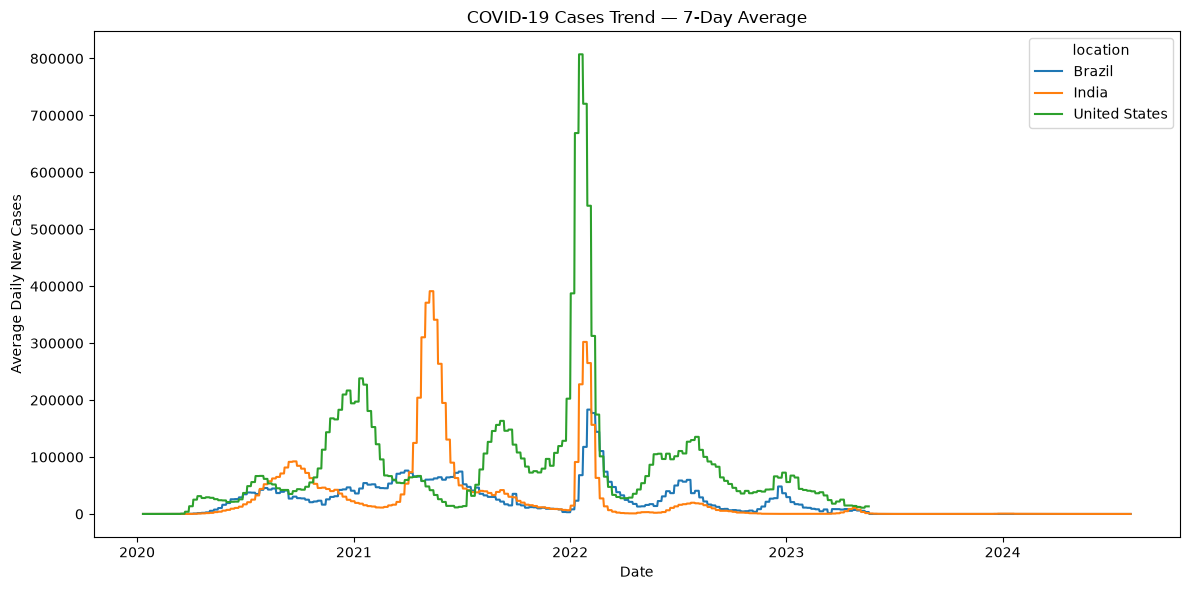

In [10]:
#COVID-19 cases trend
if "new_cases_7day_avg" in df.columns:
    countries = ["India", "United States", "Brazil"]

    plot_df = df[df["location"].isin(countries)].copy()

    plt.figure(figsize=(12, 6))

    sns.lineplot(
        data=plot_df,
        x="date",
        y="new_cases_7day_avg",
        hue="location"
    )

    plt.title("COVID-19 Cases Trend — 7-Day Average")
    plt.xlabel("Date")
    plt.ylabel("Average Daily New Cases")
    plt.tight_layout()

    plt.savefig(
        CHART_DIR / "05_day3_cases_7day_average.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

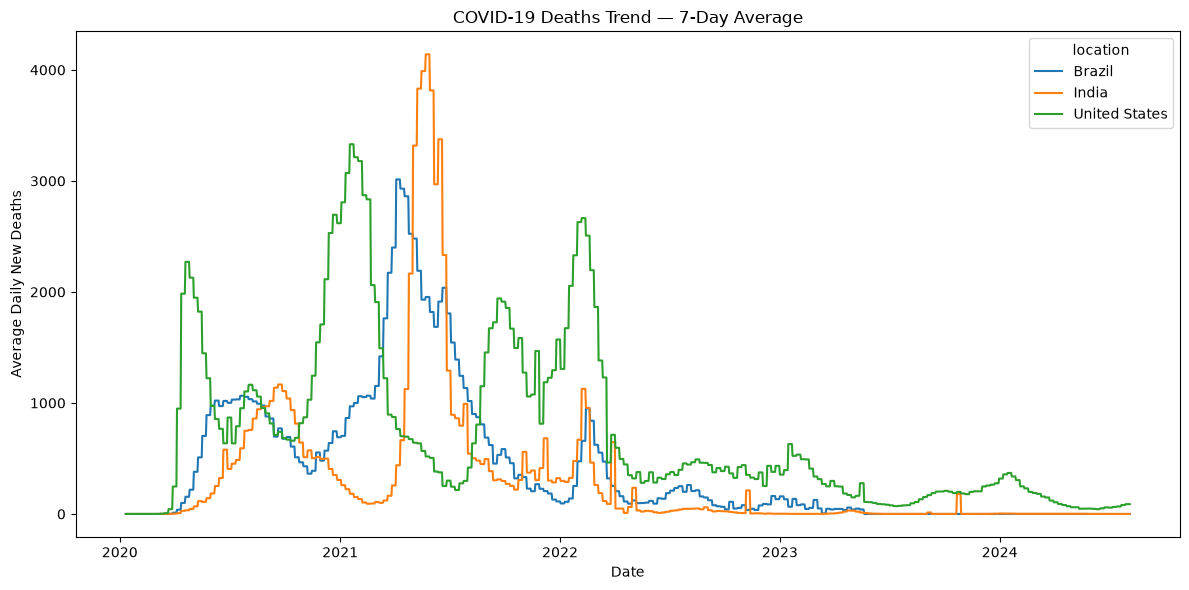

In [11]:
#COVID-19 deaths trend
if "new_deaths_7day_avg" in df.columns:
    countries = ["India", "United States", "Brazil"]
    plot_df = df[df["location"].isin(countries)].copy()

    plt.figure(figsize=(12, 6))

    sns.lineplot(
        data=plot_df,
        x="date",
        y="new_deaths_7day_avg",
        hue="location"
    )

    plt.title("COVID-19 Deaths Trend — 7-Day Average")
    plt.xlabel("Date")
    plt.ylabel("Average Daily New Deaths")
    plt.tight_layout()

    plt.savefig(
        CHART_DIR / "06_day3_deaths_7day_average.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

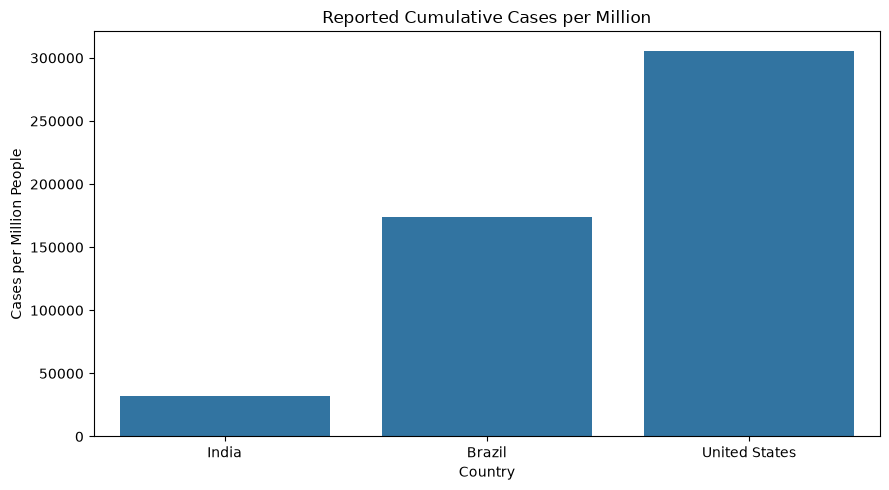

             location       date  cases_per_million
163785          India 2024-08-04       31782.812815
48549          Brazil 2024-08-04      174220.010836
376895  United States 2024-08-04      305763.909752


In [12]:
#Compare countries by cases per million
if "cases_per_million" in df.columns:
    latest = (
        df.dropna(subset=["cases_per_million"])
        .sort_values("date")
        .groupby("location")
        .tail(1)
        .copy()
    )

    selected = latest[
        latest["location"].isin(
            ["India", "United States", "Brazil"]
        )
    ]

    if not selected.empty:
        plt.figure(figsize=(9, 5))

        sns.barplot(
            data=selected,
            x="location",
            y="cases_per_million"
        )

        plt.title("Reported Cumulative Cases per Million")
        plt.xlabel("Country")
        plt.ylabel("Cases per Million People")
        plt.tight_layout()

        plt.savefig(
            CHART_DIR / "07_day3_cases_per_million.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()

        print(selected[[
            "location", "date", "cases_per_million"
        ]])

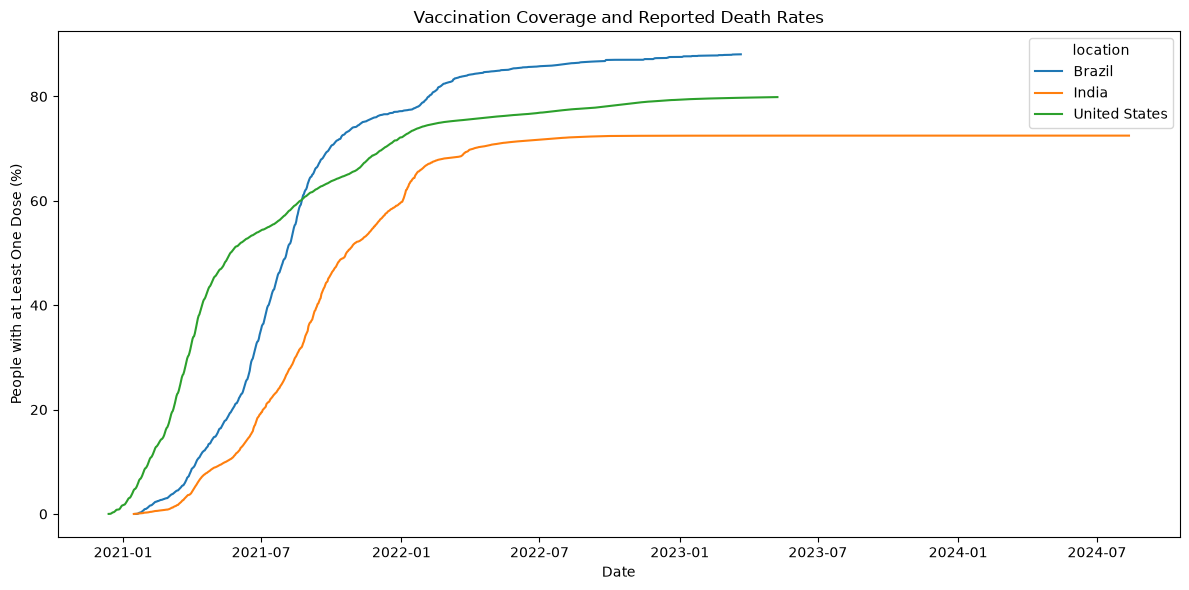

In [13]:
#Compare vaccination and mortality trends
if {
    "vaccinated_pct", "deaths_per_million"
}.issubset(df.columns):

    countries = ["India", "United States", "Brazil"]

    plot_df = df[
        df["location"].isin(countries)
    ].copy()

    fig, ax1 = plt.subplots(figsize=(12, 6))

    sns.lineplot(
        data=plot_df,
        x="date",
        y="vaccinated_pct",
        hue="location",
        ax=ax1
    )

    ax1.set_title(
        "Vaccination Coverage and Reported Death Rates"
    )
    ax1.set_xlabel("Date")
    ax1.set_ylabel("People with at Least One Dose (%)")

    plt.tight_layout()

    plt.savefig(
        CHART_DIR / "08_day3_vaccination_coverage.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

In [14]:
df = df.sort_values(["location", "date"])

df.to_csv(OUTPUT_PATH, index=False)

print("Day 3 analysis completed!")
print("Output saved to:", OUTPUT_PATH)
print("Final dataset shape:", df.shape)
print("Charts saved in:", CHART_DIR)

Day 3 analysis completed!
Output saved to: D:\Veda Internship\Sakshi\Super_Store_DataCleaning\COVID19_Global_Impact_Dashboard\Day3_Covid19_Global_Impact_Dashboard\cleaned_data\covid19_day3_analysis.csv
Final dataset shape: (395311, 77)
Charts saved in: D:\Veda Internship\Sakshi\Super_Store_DataCleaning\COVID19_Global_Impact_Dashboard\Day3_Covid19_Global_Impact_Dashboard\charts


In [15]:
countries = ["India", "United States", "Brazil"]

summary_columns = [
    "location", "date", "cases_per_million",
    "deaths_per_million", "case_fatality_rate",
    "vaccinated_pct", "fully_vaccinated_pct"
]

summary_columns = [
    col for col in summary_columns if col in df.columns
]

country_summary = (
    df[df["location"].isin(countries)]
    .sort_values("date")
    .groupby("location")
    .tail(1)[summary_columns]
)

display(country_summary)

,location,date,cases_per_million,deaths_per_million,case_fatality_rate,vaccinated_pct,fully_vaccinated_pct
376895,United States,2024-08-04,305763.909752,3527.049301,1.153520,NaN,NaN
48549,Brazil,2024-08-04,174220.010836,3260.900905,1.871714,NaN,NaN
163793,India,2024-08-12,NaN,NaN,NaN,72.499182,67.175318


### Finding 1 — COVID-19 waves

The 7-day rolling average shows changes in reported COVID-19 cases over time, with peaks during major waves of infection. After each peak, the average generally decreased as reported case numbers declined. The exact peak period should be confirmed using the cases trend chart.

### Finding 2 — Country comparison

Among the selected countries,the United States recorded the highest reported cumulative cases per million, at approximately 305,763.91 in the displayed comparison. Brazil recorded approximately 174,220.01 cases per million. These figures reflect reported infections, not every infection that occurred.

### Finding 3 — Mortality

The reported deaths-per-million figures were highest in the United States (approximately 3,527.05), followed by Brazil (approximately 3,260.90), among the available values in the displayed comparison. India's latest displayed record has missing values, so a complete three-country comparison is not possible from this table. Differences in testing, reporting, demographics, and healthcare access may contribute to the observed pattern.

### Finding 4 — Vaccination rollout

The dataset contains vaccination coverage information for India, including approximately 72.50% with at least one vaccine dose and 67.18% fully vaccinated in the displayed record. The vaccination rollout period and its relationship with deaths per million should be confirmed by comparing the historical trends over the same period before drawing conclusions.

### Finding 5 — Case fatality rate

The displayed case fatality rate was approximately 1.15% for the United States and 1.87% for Brazil in the latest available records shown. To describe how this metric changed over the period studied, the beginning and ending values for the same country must be compared. This metric can change with testing, case detection, and the timing of deaths.

In [16]:
for country in ["India", "United States", "Brazil"]:
    country_df = (
        df[df["location"] == country]
        .sort_values("date")
    )

    print(f"\n--- {country} ---")

    for col in [
        "new_cases_7day_avg",
        "deaths_per_million",
        "vaccinated_pct",
        "fully_vaccinated_pct",
        "case_fatality_rate"
    ]:
        if col in country_df.columns:
            valid = country_df.dropna(subset=[col])

            if not valid.empty:
                print(
                    f"{col}: "
                    f"{valid.iloc[0]['date']} = "
                    f"{valid.iloc[0][col]:.2f}; "
                    f"{valid.iloc[-1]['date']} = "
                    f"{valid.iloc[-1][col]:.2f}"
                )


--- India ---
new_cases_7day_avg: 2020-01-11 00:00:00 = 0.00; 2024-08-04 00:00:00 = 44.71
deaths_per_million: 2020-01-05 00:00:00 = 0.00; 2024-08-04 00:00:00 = 376.54
vaccinated_pct: 2021-01-15 00:00:00 = 0.00; 2024-08-12 00:00:00 = 72.50
fully_vaccinated_pct: 2021-02-13 00:00:00 = 0.00; 2024-08-12 00:00:00 = 67.18
case_fatality_rate: 2020-02-02 00:00:00 = 0.00; 2024-08-04 00:00:00 = 1.18

--- United States ---
new_cases_7day_avg: 2020-01-11 00:00:00 = 0.00; 2023-05-20 00:00:00 = 13322.86
deaths_per_million: 2020-01-05 00:00:00 = 0.00; 2024-08-04 00:00:00 = 3527.05
vaccinated_pct: 2020-12-13 00:00:00 = 0.01; 2023-05-09 00:00:00 = 79.88
fully_vaccinated_pct: 2020-12-13 00:00:00 = 0.00; 2023-05-09 00:00:00 = 68.18
case_fatality_rate: 2020-01-26 00:00:00 = 0.00; 2024-08-04 00:00:00 = 1.15

--- Brazil ---
new_cases_7day_avg: 2020-01-11 00:00:00 = 0.00; 2024-08-04 00:00:00 = 0.00
deaths_per_million: 2020-01-05 00:00:00 = 0.00; 2024-08-04 00:00:00 = 3260.90
vaccinated_pct: 2021-01-17 00:00: